# Am-Be moderado, haz horizontal y PMT bajado

Análisis de las tres corridas de 500 000 neutrones (10 meV–10 eV) con el PMT a 0.3·H/2, en agua pura y con 2.5 y
10 % de NaCl. Se comparan con el prototipo por **factores comunes**: un k horizontal (ADC/p.e.) y un N vertical
(neutrones en 300 s), los mismos para los tres medios. La calibración con muones del PMT bajado solo se usa si
cumple el criterio fijado (sección 3). Informe: `informe/Informe-PMT-bajo-horizontal.pdf`.

Las corridas se leen del disco ADATA (`ADATA`). Si los `.npz` ya existen en `resultados/`, el paso 1 se salta.

In [1]:
import json, os, subprocess, sys
from IPython.display import Image, display
BASE = os.path.abspath(".")
M = os.path.abspath(os.path.join(BASE, "..", "Analisis-montaje-MEIGA", "scripts"))
ADATA = os.environ.get("ADATA", "ADATA HD330/Corrida-AmBe-horizontal-PMT-bajo-resultados")
CORRIDAS = {"pura_horiz": "500000N-AmBe-moderado-horizontal-PMTbajo-H2O-pura-sinSab-20261023-081659",
            "nacl25_horiz": "500000N-AmBe-moderado-horizontal-PMTbajo-H2O-2.5NaCl-sinSab-20261023-101321",
            "nacl10_horiz": "500000N-AmBe-moderado-horizontal-PMTbajo-H2O-10NaCl-sinSab-20261023-132027"}
MUONES = os.path.join(ADATA, "2000N-muones-VEM-PMTbajo-H2O-pura-sinSab-20261023-040805")
def correr(*args):
    r = subprocess.run([sys.executable, *args], cwd=BASE, capture_output=True, text=True)
    if r.returncode: raise RuntimeError(r.stderr[-2000:])
    return r.stdout

## 1. Procesamiento por evento (`procesar_montaje.py`)

In [2]:
for et, carpeta in CORRIDAS.items():
    if not os.path.exists(f"resultados/eventos_{et}.npz"):
        correr(os.path.join(M, "procesar_montaje.py"), os.path.join(ADATA, carpeta), et, "resultados")
    v = json.load(open(f"resultados/verificacion_{et}.json"))
    print(et, v["eventos_total"], "eventos; máx. dif. rel. de energía:",
          max(p["max_dif_rel_energia"] for p in v["partes"].values()))

pura_horiz 500000 eventos; máx. dif. rel. de energía: 8.423718664595062e-06
nacl25_horiz 500000 eventos; máx. dif. rel. de energía: 8.423718664595062e-06
nacl10_horiz 500000 eventos; máx. dif. rel. de energía: 8.423718664595062e-06


## 2. Factores comunes k y N
Con la resolución de 1 p.e. (`ajuste_factor_comun.py`) y con la electrónica completa (`respuesta_prototipo.py --k-libre`).

ventana_trigger k = 650.0 ADC/p.e.;  N = 6.15e+06 ;  rms = 0.808
robusto k = 625.0 ADC/p.e.;  N = 7.6e+06 ;  rms = 0.83


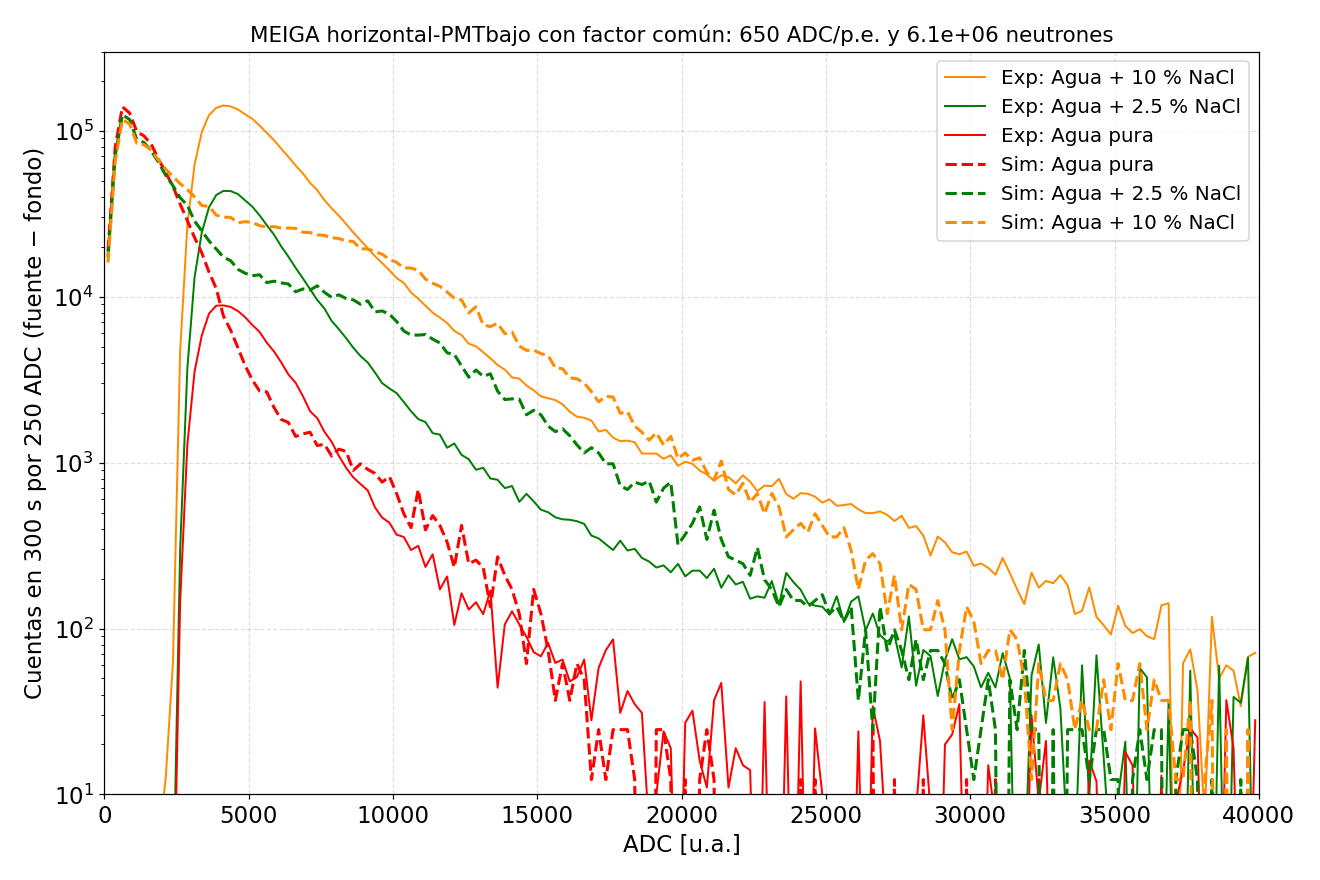

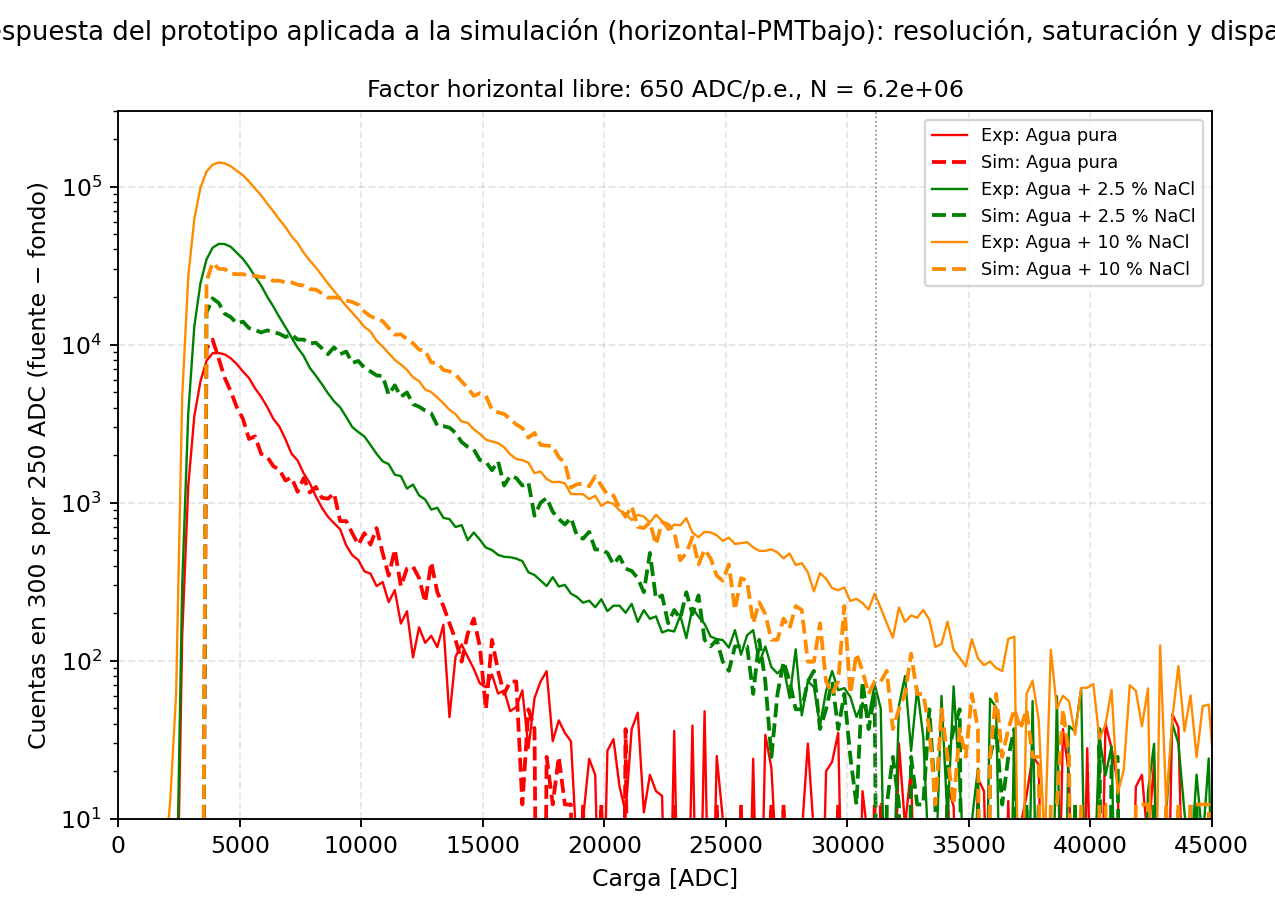

In [3]:
correr(os.path.join(M, "ajuste_factor_comun.py"), "--eventos", *CORRIDAS, "--calibracion", "calibracion_vem_pmtbajo.json",
       "--etiqueta", "horizontal-PMTbajo", "--salida", BASE)
if os.path.isdir(MUONES):
    correr(os.path.join(M, "respuesta_prototipo.py"), "--muones", MUONES,
           "--medio", "pura", "resultados/eventos_pura_horiz.npz", "--medio", "2.5", "resultados/eventos_nacl25_horiz.npz",
           "--medio", "10", "resultados/eventos_nacl10_horiz.npz", "--etiqueta", "horizontal-PMTbajo",
           "--k-libre", "--sin-panel-muones", "--salida", BASE)
F = json.load(open("resultados/ajuste_factor_comun_horizontal-PMTbajo.json"))
for met in ("ventana_trigger", "robusto"):
    print(met, "k =", F[met]["k_ADC_por_pe"], "ADC/p.e.;  N =", f"{F[met]['N_inc_300s']:.3g}", ";  rms =", round(F[met]["rms_ln"], 3))
display(Image("figuras/fig10b_histogramas_factor_comun_horizontal-PMTbajo.png"))
display(Image("figuras/fig14_respuesta_prototipo_horizontal-PMTbajo.png"))

## 3. ¿Se usa la calibración con muones?
Criterio: 0.67 ≤ k/k_μ ≤ 1.5, rms(k_μ) ≤ 1.25·rms(k), y ≥ 80 % de bins con simulación usando k_μ, en los tres medios.

In [4]:
D = json.loads(correr("scripts/decidir_calibracion_muones.py"))
for met, r in D["metodos"].items():
    print(met, {k: round(r[k], 3) for k in ("cociente_k_libre_sobre_muones", "rms_muones_sobre_libre", "fraccion_bins_min_con_muones")}, "pasa:", r["pasa"])
print("Implementar la calibración con muones:", D["implementar_calibracion_muones"])

ventana_trigger {'cociente_k_libre_sobre_muones': 9.807, 'rms_muones_sobre_libre': 2.54, 'fraccion_bins_min_con_muones': 0.0} pasa: False
robusto {'cociente_k_libre_sobre_muones': 9.43, 'rms_muones_sobre_libre': 2.542, 'fraccion_bins_min_con_muones': 0.0} pasa: False
Implementar la calibración con muones: False


## 4. Respuesta del detector

pura    eps=0.163  disparo=0.0131  eta_cap=0.337  <Q>=2.71 p.e.  tau=134 us  (tapa: eps=0.103)
nacl25  eps=0.212  disparo=0.0685  eta_cap=0.384  <Q>=5.66 p.e.  tau=105 us  (tapa: eps=0.143)
nacl10  eps=0.293  disparo=0.1455  eta_cap=0.482  <Q>=7.79 p.e.  tau=61 us  (tapa: eps=0.209)


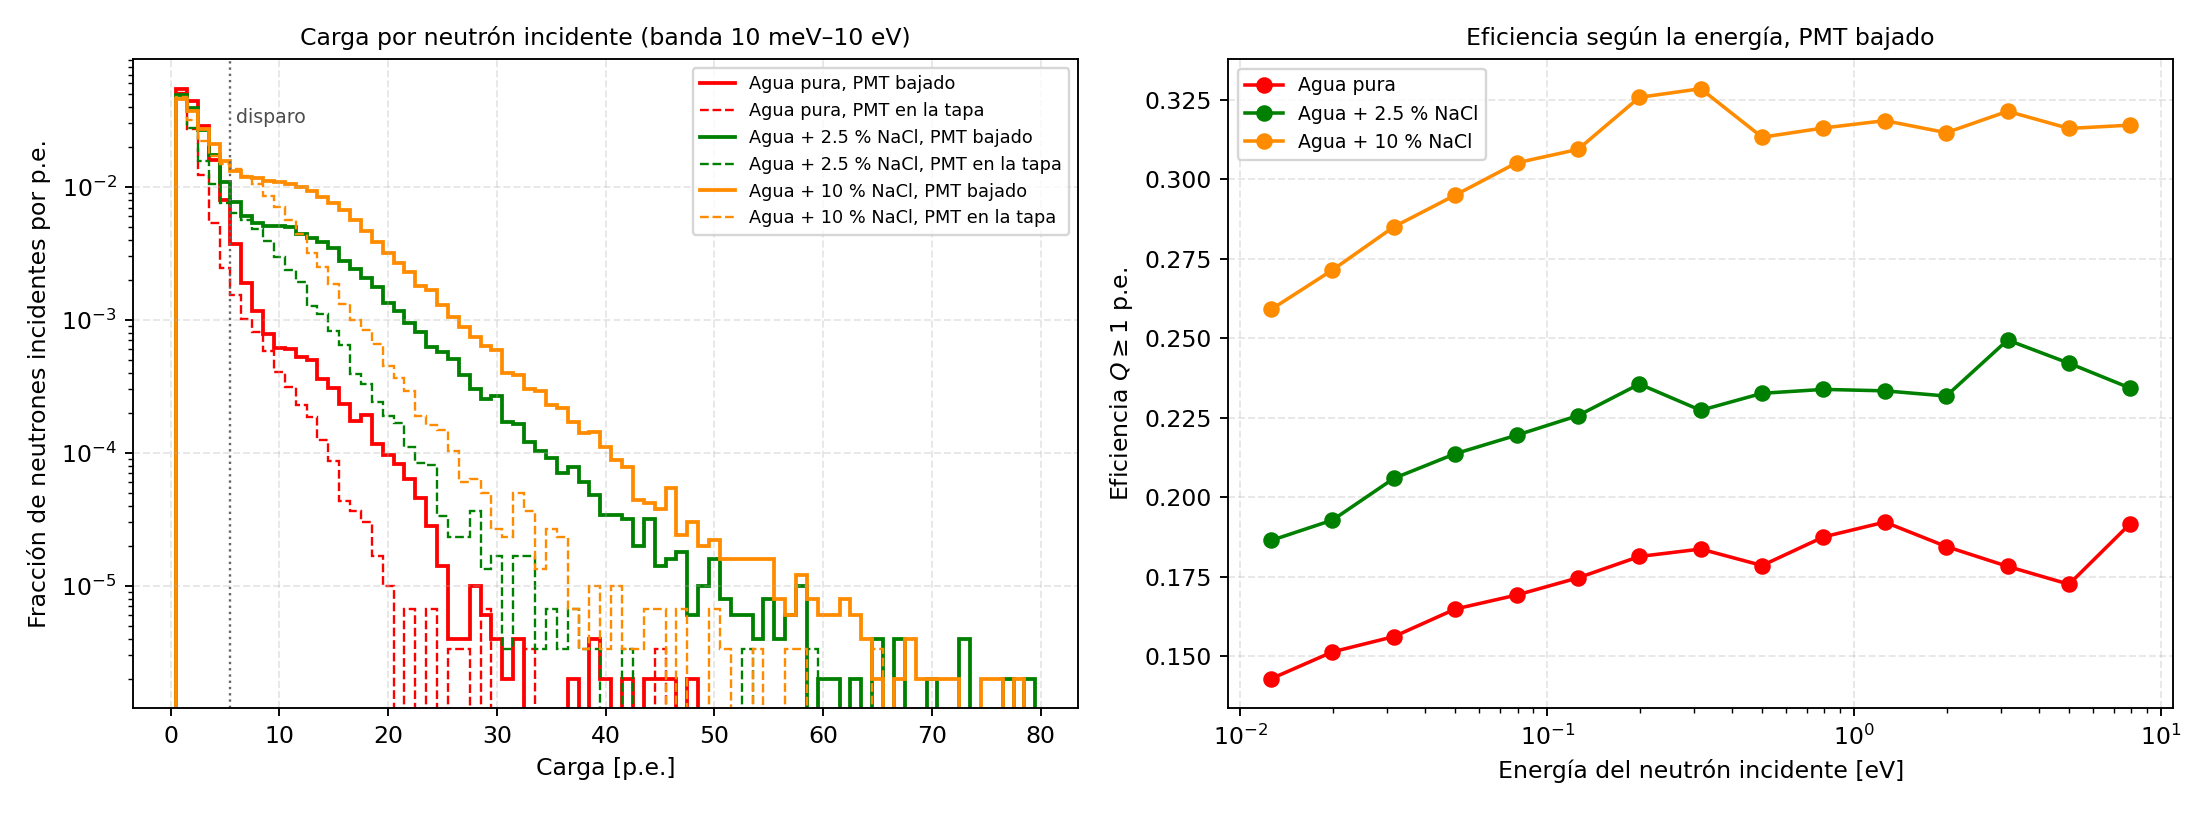

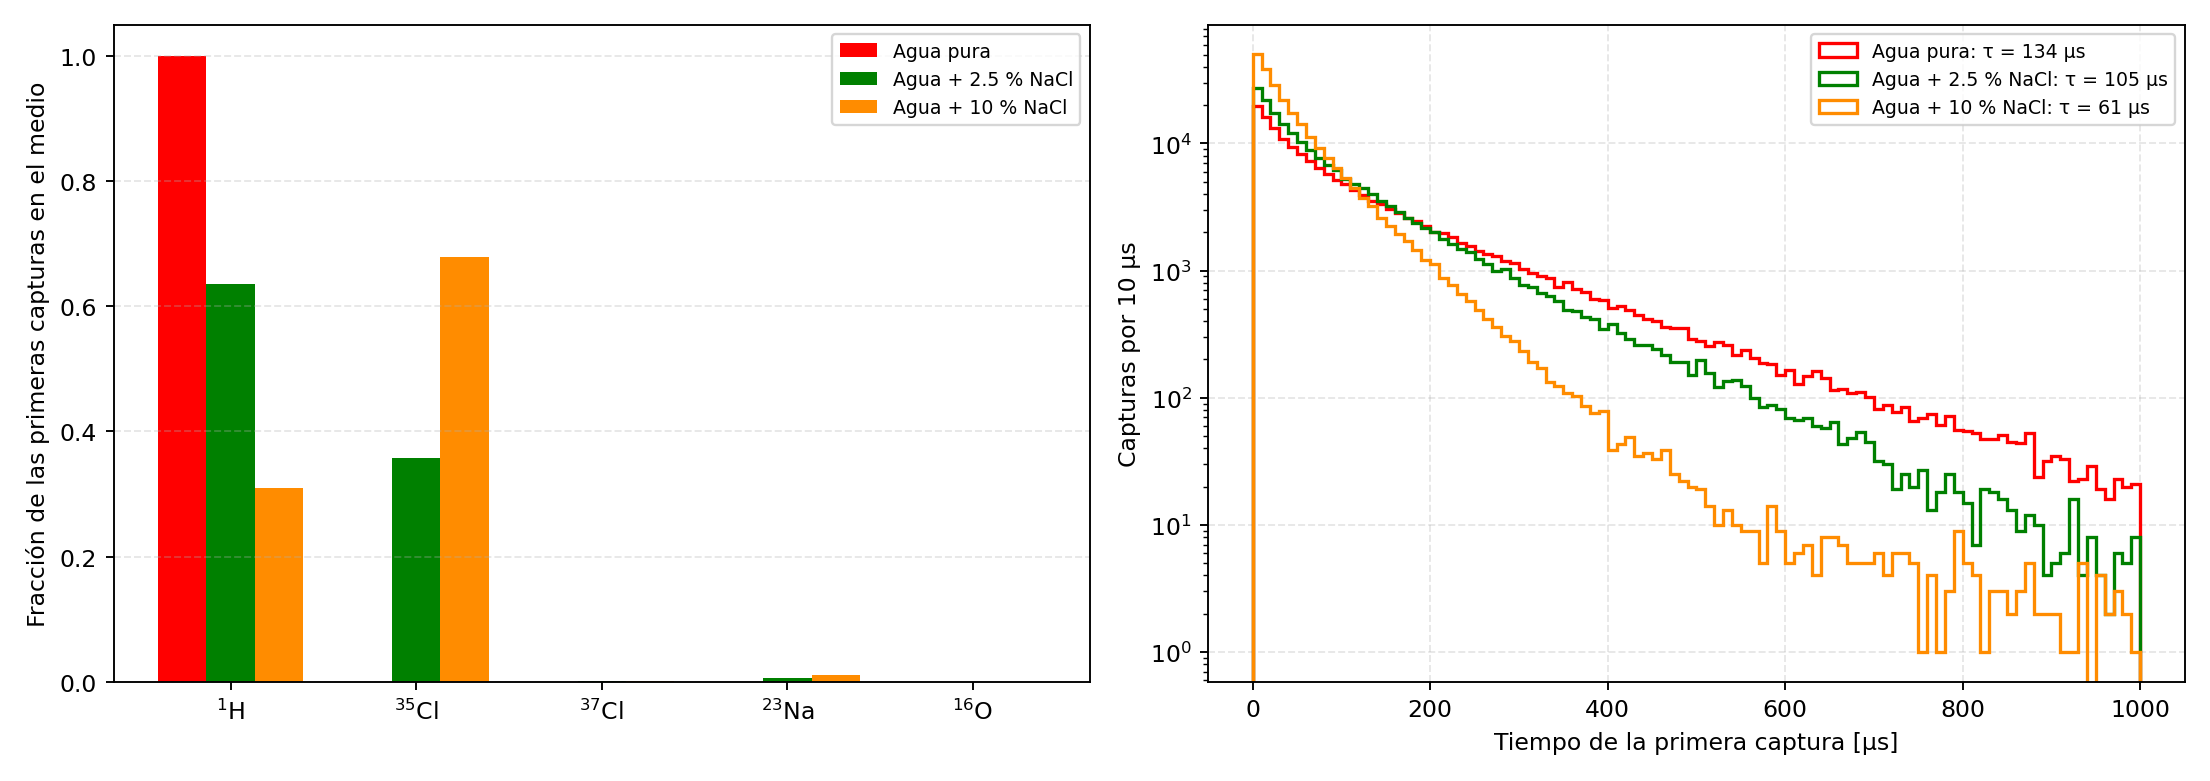

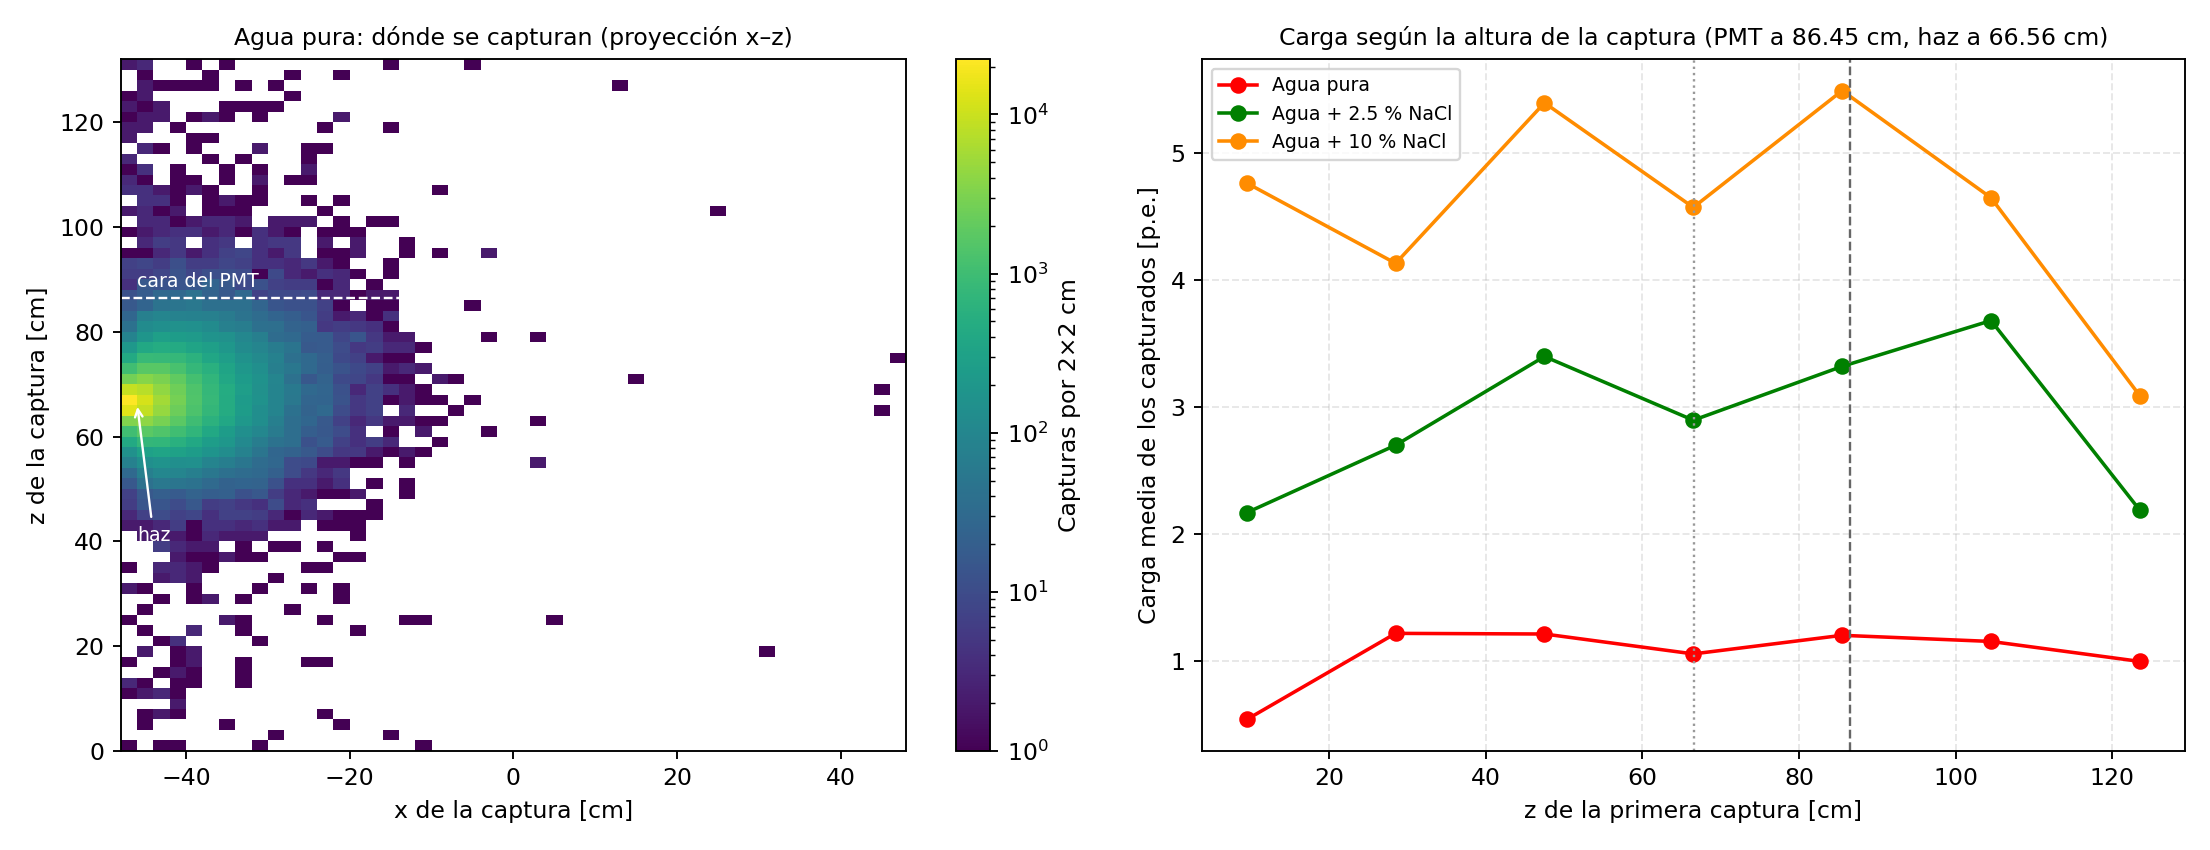

In [5]:
correr("scripts/analizar_horizontal_pmtbajo.py")
R = json.load(open("resultados/resumen_horizontal.json"))
for m, r in R["medios"].items():
    print(f"{m:7s} eps={r['eps_Q1']:.3f}  disparo={r['eps_disparo_electronica']:.4f}  eta_cap={r['eta_cap_medio']:.3f}  "
          f"<Q>={r['Q_media_senal']:.2f} p.e.  tau={r['tau_cola_us']:.0f} us  (tapa: eps={r['tapa_misma_banda']['eps_Q1']:.3f})")
for f in ("fig01_carga_eficiencia", "fig02_capturas", "fig03_posicion_captura"):
    display(Image(f"figuras/{f}.png"))